In [12]:
import pandas as pd
import os
import glob, os
from tqdm.notebook import tqdm
import json

pd.set_option('display.max_columns', None)

# Datos electorales

In [2]:
data_path = "../data/raw/resultados_electorales/congreso_por_municipio/"
df = None
for file in tqdm(glob.glob(data_path + "*.xlsx")):
    file_path = file
    if df is None:
        df = pd.read_excel(file_path, header=1, skiprows=4)
    else:
        df_single = pd.read_excel(file_path, header=1, skiprows=4)
        year = os.path.splitext(file_path)[0].split("/")[-1][3:7]
        month = os.path.splitext(file_path)[0].split("/")[-1][7:9]
        df_single["Año"] = int(year)
        df_single["Mes"] = int(month)
        df_single["añomes"] = year+month
        df = pd.concat([df, df_single], ignore_index=True, sort=False)

In [41]:
df.columns

Index(['Nombre de Comunidad', 'Código de Provincia', 'Nombre de Provincia',
       'Código de Municipio', 'Nombre de Municipio', 'Población',
       'Número de mesas', 'Total censo electoral', 'Total votantes',
       'Votos válidos',
       ...
       'L.I. (LIT-CI)', 'ZU', 'Ud Ca', 'FDE', 'PSDA', 'AMAGA', 'PNT', 'CCSE',
       'PDN', 'GPHAE'],
      dtype='object', length=762)

In [43]:
# limpiar columnas index y rellenar NA
df = df[df.columns.drop(list(df.filter(regex='Unnamed')))]
df = df.fillna(0)
# eliminar columnas con menso de x votos
#df_sum = pd.DataFrame(df.sum(axis = 0, skipna = True, numeric_only=True))
#df_sum[df_sum[0] == 0].index

In [46]:
# crear codigo ine
df["CODIGOINE"] = df["Código de Provincia"].astype(int).astype(str) + df["Código de Municipio"].astype(int).astype(str).str.zfill(3)

In [47]:
df.tail()

,Nombre de Comunidad,Código de Provincia,Nombre de Provincia,Código de Municipio,Nombre de Municipio,Población,Número de mesas,Total censo electoral,Total votantes,Votos válidos,Votos a candidaturas,Votos en blanco,Votos nulos,PP,PSOE,IU,CIU,EAJ-PNV,CC,BNG,HB,ERC,PA,EA,UV,LVE,CHA,UC,UPV-BN,PSM-ENE,CDN,LV-GV,PRT,PCPE,PH,PAS,UPL,FEA,ICV-GORORDO,LV,CEX,UM,TC-PNC,P.RIOJANO,PEC,URCL,NA,AUN,CR,SOS,PREPAL,FREPIC,PSPC,PRCM,FPG,SIEX,PRV,PRIM,FEI,NR,PICC,AR,ENV,PAE,PB,PCN,UPRA,UAD,ADEC,VDPA,N,ALAS,ABA,PRGU,LAE,DSA,LG,PIZ,PNM,POR,AFIT,CCV,PSOE,PP,Cs,PODEMOS-IU-EQUO,VOX,ERC-SOBIRANISTES,ECP-GUANYEM EL CANVI,JxCAT-JUNTS,EAJ-PNV,EH Bildu,PODEMOS-EU-MAREAS EN COMÚN-EQUO,CCa-PNC,NA+,COMPROMÍS 2019,PRC,PACMA,FRONT REPUBLICÀ,BNG,RECORTES CERO-GV,NCa,PACT,ARA-MES-ESQUERRA,GBAI,PUM+J,EN MAREA,PCTE,EL PI,AxSI,PCOE,PCPE,AVANT ADELANTE LOS VERDES,EB,CpM,SOMOS REGIÓN,PCPA,PH,UIG-SOM-CUIDES,ERPV,IZQP,PCPC,AHORA CANARIAS,CxG,PPSO,CNV,PREPAL,C.Ex-C.R.Ex-P.R.Ex,PR+,P-LIB,CILU-LINARES,ANDECHA ASTUR,"""JF""",PYLN,FIA,FE de las JONS,F8,SOLIDARIA,DPL,UNIÓN REGIONALISTA,centrados,VOU,DP,PDSJE-UDEC,IZAR,RISA,C 21,+MAS+,UDT,Año,Mes,añomes,AP-PDP,UCD,PCE,CDS,FN,PST,EE,PSA-PA,PCC,B-PSG,UPC,NE,SE,UCE,PCOE,PCE (M-L),EU,EG,AC-CC,UPV,CUC,PS,MFE,EUPV,AEBA,PSM,LC (COSI),PSA,ENV-URV,AEGI,CE-FCC,FE-JONS,FIC,PNC,PADL,CC.1,IDG,FE-I,LCR-MC,LCR,ACI,PRE,PNC.1,PDB,M.CAT.E,ASDC,IR,FA,EM,PCU,PC,EMK,BIA,CIR,PARTIDO POPULAR,PARTIDO SOCIALISTA OBRERO ESPAÑOL,CIUDADANOS-PARTIDO DE LA CIUDADANÍA,PODEMOS,EN COMÚ PODEM,"UNIDAD POPULAR: IZQUIERDA UNIDA, UNIDAD POPULAR EN",COMPROMÍS-PODEMOS-ÉS EL MOMENT,ESQUERRA REPUBLICANA DE CATALUNYA-CATALUNYA SÍ,DEMOCRÀCIA I LLIBERTAT. CONVERGÈNCIA. DEMÒCRATES.,EUZKO ALDERDI JELTZALEA-PARTIDO NACIONALISTA VASCO,PARTIDO ANIMALISTA CONTRA EL MALTRATO ANIMAL,EUSKAL HERRIA BILDU,UNIÓN PROGRESO Y DEMOCRACIA,COALICIÓN CANARIA - PARTIDO NACIONALISTA CANARIO,NÓS-CANDIDATURA GALEGA (BNG-CG-FOGA-PCPG-PG),UNIÓ DEMOCRÀTICA DE CATALUNYA,RECORTES CERO-GRUPO VERDE,MÉS,PARTIDO COMUNISTA DE LOS PUEBLOS DE ESPAÑA,GEROA BAI,EL PI - PROPOSTA PER LES ILLES,CIUDADANOS DE CENTRO DEMOCRÁTICO,ESCAÑOS EN BLANCO,FALANGE ESPAÑOLA DE LAS J.O.N.S.,X LA IZQUIERDA-LOS VERDES,SOM VALENCIANS,POR UN MUNDO MÁS JUSTO,SOLIDARIDAD Y AUTOGESTIÓN INTERNACIONALISTA,LOS VERDES-ECOPACIFISTAS,PARTIDO DA TERRA,"CANARIAS DECIDE: LOS VERDES, UNIDAD DEL PUEBLO Y A",PARTIDO LIBERTARIO,PARTIDO HUMANISTA,"ARA, PAÍS VALENCIÀ",EXTREMADURA UNIDA-EXTREMEÑOS,PARTIDO COMUNISTA OBRERO ESPAÑOL,DEMOCRACIA NACIONAL,INICIATIVA FEMINISTA,PARTIDO REGIONALISTA DEL PAÍS LEONES,EN POSITIU,CIUDADANOS LIBRES UNIDOS,CIUDADANOS RURALES AGRUPADOS,"LIBERTAD NAVARRA, LIBERTATE NAFARRA",AVANT VALENCIANS,MÁLAGA POR SÍ,FAMILIA Y VIDA,ANDALUCES DE JAÉN UNIDOS,INDEPENDIENTES POR ARAGÓN,FORO DEMÓCRATA,SOLUCIONA,"JUSTIZIA SOCIAL, PARTICIPACIÓN CIUDADANA",MUERTE AL SISTEMA,PARTIDO LIBERAL DE DERECHAS,ONGI ETORRI,RUIZ-MATEOS,LV-LV,PTE-UC,PAR,AIC,CG,PSG-EG,AV-MEC,VERDE,ACN,CSD,PNG-PG,EX.U.,PORE,IGC,PED,PAM,GRM,UNA,UA-CH.A,UB,CEU,ARDE,SEV,MV,PANCAL,COA,PEE-(LV),R. X C.,FE (I),TAGOROR,PRB,PNEM,P.PR.,LKI-EMK,PCE-(M.L.),CD,UN,PNV,PTE,PSOE-H,ORT,ERFN,MC-OIC,BNPG,C-UPC,PG-POG-PSG,BEAN,PCARL,PCT,UFV,FJONSA,UPN,OCE-BR,PSAR - PSDA,PLIB,URV,PNPV,UNAI,PDPCAN,SMIM,PSIN,ULE,E CATALA,CIC,P-CANT,DSCC,PPROV,LC,OCEBR-UCE,CNA,PIPPA,POC,CIME,FE-UF,UF-FI-AT,VERDES,EA-EUE,LE,ARM-ADE,PAP,UPCA,PRC,UA,GIL,PGC,PLN,E U,UMMP,PEC-VERDE,NPS,P. RIOJANO,CNG,AG,PREX,SEES,ARCOIRIS,APP,PVPA,MCE,ATF,AIGRANC,FPE,AA,FE (A),UNI.D.A,UDLA,OS,CONCEYU,PIAP,ABE,PITRCG,IF,P. TAGOROR,MCES,US,INCE,FREIXES,CCL,AP,PSP-US,PDPC,FDC-EDC,UDC-IDCC,EC-FED,FDI,ASDCI,AET,AN18,RSE,FUT,CAIC,ESB,PSPV,INDEP,DCV,PSG,FJONS,AFN,INDEP.1,URA,LLIGA,UAN,ANEPA-CP,FL,DIV,CJA,CUPS,CCIA,UAB,URAS,FNI,PPCAN,MS,ASA,MFA,ANV,INDEP.2,INDEP.3,INDEP.4,DCAR,UDIB,INDEP.5,CUP,PSCAN,FAA,PIM,INDEP.6,PRSV,ICU,PSDE,INDEP.7,INDEP.8,PDG,INDEP.9,INDEP.10,INDEP.11,AEICYU,CUIR,CIPYE,PLI,ADC,BAI,INDEP.12,CAI,PSOE-PROGR.,IC-V,BLOC-VERDS,PSM-EN,UC-CDS,LV-CM,FE,POSI,EV-AV,PIL,ES2000,PADE,UM-INME,IA,BLM,FEI-FE 2000,PCL,AU.TO.NO

In [5]:
df.shape

(121362, 762)

In [6]:
df.dtypes

Nombre de Comunidad     object
Código de Provincia    float64
Nombre de Provincia     object
Código de Municipio    float64
Nombre de Municipio     object
                        ...   
AMAGA                  float64
PNT                    float64
CCSE                   float64
PDN                    float64
GPHAE                  float64
Length: 762, dtype: object

# Mapa España por munipios

In [25]:
import geopandas as gpd
map_path = "../data/raw/mapa_municipios/Municipios_IGN-shp/Municipios_IGN.shp"
geodf = gpd.read_file(map_path)

In [26]:
save_geojson_path = "../data/raw/mapa_municipios/Municipios_IGN-shp/Municipios_IGN.geojson"
geodf.to_file(save_geojson_path, driver = "GeoJSON")
with open(save_geojson_path) as geofile:
    geojson = json.load(geofile)

<AxesSubplot:>

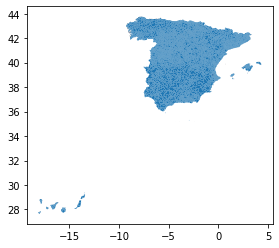

In [27]:
geodf.plot()

In [28]:
geodf.head()

,FID,INSPIREID,NATCODE,NAMEUNIT,CODNUT1,CODNUT2,CODNUT3,CODIGOINE,SHAPE_Leng,SHAPE_Area,geometry
0,1,ES.IGN.SIGLIM34081616266,34081616266,Villarejo-Periesteban,ES4,ES42,ES423,16266,0.269748,0.003520,"POLYGON ((-2.47791 39.88027, -2.47793 39.88074..."
1,2,ES.IGN.SIGLIM34081616269,34081616269,Villares del Saz,ES4,ES42,ES423,16269,0.447608,0.007382,"POLYGON ((-2.58669 39.85793, -2.58601 39.85842..."
2,3,ES.IGN.SIGLIM34081616270,34081616270,Villarrubio,ES4,ES42,ES423,16270,0.305394,0.002978,"POLYGON ((-2.96423 39.95773, -2.96231 39.95816..."
3,4,ES.IGN.SIGLIM34081616271,34081616271,Villarta,ES4,ES42,ES423,16271,0.283123,0.002680,"POLYGON ((-1.68041 39.46783, -1.67391 39.46654..."
4,5,ES.IGN.SIGLIM34081616272,34081616272,Villas de la Ventosa,ES4,ES42,ES423,16272,0.595828,0.015355,"POLYGON ((-2.49911 40.26601, -2.49878 40.26597..."


In [49]:
geodf.dtypes

FID              int64
INSPIREID       object
NATCODE         object
NAMEUNIT        object
CODNUT1         object
CODNUT2         object
CODNUT3         object
CODIGOINE       object
SHAPE_Leng     float64
SHAPE_Area     float64
geometry      geometry
dtype: object